In [1]:
import sys
sys.path.append('/nfs/dataset-ofs-385-143496/yangliu/lite-fea-workspace/wh/demo/thirdparty/copersona/')
from copersona.utils import dmpax, tools


app_name = "home_company_fix56790993302"
spark2conf = {
    "master": "yarn",
    "spark.submit.deployMode": "client",
    "driver-memory": "4g",
    "spark.dynamicAllocation.enabled": "true",
    "spark.dynamicAllocation.minExecutors": "40",
    "spark.dynamicAllocation.maxExecutors": "60",
    "spark.executor.cores": "4",
    "spark.executor.memory": "6g",
    "spark.default.parallelism": "1000",
    "spark.sql.shuffle.partitions": "1000",
    "spark.yarn.queue": "root.profile_prod",
    "spark.sql.autoBroadcastJoinThreshold": "-1",
    "spark.sql.broadcastTimeout": "3000",
    "spark.driver.extraJavaOptions": "-Dcom.github.fommil.netlib.BLAS=com.github.fommil.netlib.F2jBLAS",
    "spark.executor.extraJavaOptions": "-Dcom.github.fommil.netlib.BLAS=com.github.fommil.netlib.F2jBLAS",
    "spark.yarn.dist.archives": "hdfs://difed/user/dm/ENV/dlflow/1.0.1/py3.7.5_for_tfcluster.tgz",
    "spark.executorEnv.PYSPARK_PYTHON": "./py3.7.5_for_tfcluster.tgz/py3.7.5_for_tfcluster/bin/python3",
    "spark.jars": (
        "hdfs://difed/user/dm/ENV/jars/spark_jars/xgboost4j-0.90.jar,"
        "hdfs://difed/user/dm/ENV/jars/spark_jars/xgboost4j-spark-0.90.jar,"
        "hdfs://difed/user/dm/ENV/jars/spark_jars/spark-tensorflow-connector_2.11-1.14.0.jar,"
        "hdfs://difed/user/dm/ENV/jars/spark_jars/tensorflow-hadoop-1.14.0.jar,"
        "hdfs://difed/user/dm/ENV/jars/spark_jars/spark-tfrecord_2.11-0.2.3.jar"
    ),
    "spark.extraListeners": "sparkmonitor.listener.JupyterSparkMonitorListener",
    "spark.driver.extraClassPath": "/opt/miniconda3/lib/python3.7/site-packages/sparkmonitor/listener_2.11.jar"
}


TF211_PY_ENV="hdfs://difed/user/dm/ENV/dlflow/v2/py3.7.15_for_tfcluster.tgz"
TF211_PY_BIN="./py3.7.15_for_tfcluster.tgz/py3.7.15_for_tfcluster/bin/python3"

TF283_PY_ENV="hdfs://difed/user/dm/ENV/zhouyc/tf2.8.3.tgz"
TF283_PY_BIN="./tf2.8.3.tgz/bin/python3"

spark3conf = {
    "master": "yarn",
    "spark.submit.deployMode": "client",
    "driver-memory": "4g",
    "spark.dynamicAllocation.enabled": "true",
    "spark.dynamicAllocation.minExecutors": "10",
    "spark.dynamicAllocation.maxExecutors": "100",
    "spark.executor.cores": "4",
    "spark.executor.memory": "6g",
    "spark.executor.memoryOverhead":"10g",
    "spark.sql.hive.manageFilesourcePartitions":"false",
    "spark.default.parallelism": "200",
    "spark.sql.shuffle.partitions": "200",
    "spark.yarn.queue": "root.profile_prod",
    "spark.sql.autoBroadcastJoinThreshold": "-1",
    "spark.sql.broadcastTimeout": "3000",
    "spark.driver.extraJavaOptions": "-Dcom.github.fommil.netlib.BLAS=com.github.fommil.netlib.F2jBLAS",
    "spark.executor.extraJavaOptions": "-Dcom.github.fommil.netlib.BLAS=com.github.fommil.netlib.F2jBLAS",
    "spark.yarn.dist.archives": "",
    "spark.executorEnv.PYSPARK_PYTHON": "",
    "spark.extraListeners": "sparkmonitor.listener.JupyterSparkMonitorListener",
    "spark.driver.extraClassPath": "/opt/miniconda3/lib/python3.7/site-packages/sparkmonitor/listener_2.12.jar",
    
    
    "spark.jars": (
        "hdfs://difed/user/dm/ENV/jars/spark_tfrecord/compile/spark-tfrecord-0.5.1_scala2.12-spark3.2.0-tfhp1.15.0.jar"
    ),   
}

spark3conf['spark.executorEnv.PYSPARK_PYTHON'] = TF211_PY_BIN
spark3conf['spark.yarn.dist.archives'] = TF211_PY_ENV

spark_app = dmpax.SparkBaseApp()
spark_app.initialize(app_name, spark3conf)
spark = spark_app.spark
hdfs = spark_app.hdfs

print("[Info] Spark Version : {}".format(spark.version))

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
Application Id: application_1782979140233_32938247, Tracking URL: http://bigdata-nmg-hdprm00.nmg01:8088/proxy/application_1782979140233_32938247/
INFO:SparkMonitorKernel:Client Connected ('127.0.0.1', 33116)
INFO:SparkMonitorKernel:Client Connected ('127.0.0.1', 33116)


[Info] Spark Version : 3.2.0-101


In [2]:
import warnings
warnings.filterwarnings("ignore")

import pyspark
import os
import json
import math
import sys
import random
import importlib
import seaborn as sns
import numpy as np
import pandas as pd
import itertools
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt


import pyspark.sql.types as T
from pyspark.files import SparkFiles
from pyspark.sql   import functions as func
from pyspark.sql   import DataFrame
from pyspark.sql.window import Window
from tqdm import tqdm
from functools import reduce



from ortools.linear_solver import pywraplp
from sklearn.metrics import roc_auc_score


sys.path.append('/nfs/dataset-ofs-385-143496/yangliu/lite-fea-workspace/wh/demo/thirdparty/backflow/')

from backflow import exp_setting
from backflow.programming import pgt
from backflow.calib import metrics as calib_metric
from backflow.calib import stats   as calib_stats
from backflow.visualization import vis
from backflow.programming import simulation as pgtsimu
from backflow.utils import tools as bkfl_tools
import datetime,json
import pandas as pd

from pyspark.sql.functions import col,desc, udf
from pyspark.sql.types import StructType
from pyspark.sql.types import StructField
from pyspark.sql.types import StringType
from pyspark.sql import DataFrame
from pyspark.sql import functions as func


importlib.reload(exp_setting)
importlib.reload(pgt)
importlib.reload(calib_metric)
importlib.reload(calib_stats)
importlib.reload(vis)
importlib.reload(pgtsimu)
importlib.reload(bkfl_tools)


pd.set_option('display.max_columns', None)

load metric func from causalml...
load metric func from causalml...


In [3]:
if True:
    import warnings
    warnings.filterwarnings("ignore")

    import pyspark
    import os
    import json
    import math
    import sys
    import random
    import importlib
    import seaborn as sns
    import numpy as np
    import pandas as pd
    import itertools
    import matplotlib.pyplot as plt
    import matplotlib.pyplot as plt


    import pyspark.sql.types as T
    from pyspark.files import SparkFiles
    from pyspark.sql   import functions as func
    from pyspark.sql   import DataFrame
    from pyspark.sql.window import Window
    from tqdm import tqdm
    from functools import reduce

    from sklearn.metrics import roc_auc_score

    import datetime,json
    import pandas as pd

    from pyspark.sql.functions import col,desc, udf
    from pyspark.sql.types import StructType
    from pyspark.sql.types import StructField
    from pyspark.sql.types import StringType
    from pyspark.sql import DataFrame
    from pyspark.sql import functions as func

    

    pd.set_option('display.max_columns', None)

In [ ]:
# 把真实label表和模型推理的数据拼接起来
# uplift_1：留存6张3元相对control组的预测 uplift；uplift_2: {8元留存5张3} 相对 {留存6张3元}的uplift. as left853_minus_left63
# left853: 模型预测的{8元留存5张3}相对control组 的总 uplift


# baseline:473个特征
label_dt是从label_di/train_di里取的，不用错开日期，直接对齐即可

In [18]:
def build_eeuen_eval_df(model_table):
    sql = f"""
    with base as (
        select
            *,
            finish_cnt_7d as label,
            cast((nvl(send_cost, 0.0)+ nvl(send_remind_cost, 0.0)+ nvl(outcall_cost, 0.0)+ nvl(remind_cost, 0.0)
                    + nvl(msg_coupon_cost_7d, 0.0)+ nvl(outcall_coupon_cost_7d, 0.0)+ nvl(outcall_coupon2_cost_7d, 0.0)) as double
            ) as cost_7d,
            if(nvl(send_success_cnt, 0) > 0 or nvl(outcall_success_cnt, 0) > 0, 1, 0) as exp_label
        from dm.ut_alg_flowback_msg_outcall_label_v2_di
        where dt between '2026-07-23' and '2026-08-06'
          and dt not in ('2026-08-02')
          and new_exp = '迭代流量'
          and (
                group_name_eve in ('留存6张5元', '留存6张3元', '8元留存5张3', '10元留存5张3')
                or (flowtree_group_name = 'DS空白' and group_name_eve = 'control_group')
          )
    ),

    mapping_data as (
        select
            pid,
            label_dt as dt,
            treatment as model_treatment,

            -- EEUEN 最终 delta_cvr，已经是 exposure_prob * exposure_uplift
            uplift_1 as left63,
            uplift_2 as left853,
            uplift_3 as left65,
            uplift_4 as left1053,

            -- EEUEN 拆解字段
            exp_label as model_exp_label,
            exposure_prob,
            exposure_uplift_1,
            exposure_uplift_2,
            exposure_uplift_3,
            exposure_uplift_4,

            cost_1,
            cost_2,
            cost_3,
            cost_4
        from {model_table}
        where label_dt between '2026-07-23' and '2026-08-06'
          and label_dt not in ('2026-08-02')
          
    ),

    prediction_agg as (
        select
            bs.*,

            case when bs.group_name_eve = '10元留存5张3' then 4
                 when bs.group_name_eve = '留存6张5元' then 3
                 when bs.group_name_eve = '8元留存5张3' then 2
                 when bs.group_name_eve = '留存6张3元' then 1
                 when bs.group_name_eve = 'control_group' then 0
                 else null
            end as real_treatment,

            mapping_data.model_treatment,

            nvl(mapping_data.left63, 999) as left63,
            nvl(mapping_data.left853, 999) as left853,
            nvl(mapping_data.left65, 999) as left65,
            nvl(mapping_data.left1053, 999) as left1053,

            case
                when nvl(mapping_data.left853, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999
                else mapping_data.left853 - mapping_data.left63
            end as left853_minus_left63,

            case
                when nvl(mapping_data.left65, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999
                else mapping_data.left65 - mapping_data.left63
            end as left65_minus_left63,

            case
                when nvl(mapping_data.left65, 999) = 999 or nvl(mapping_data.left853, 999) = 999 then 999
                else mapping_data.left65 - mapping_data.left853
            end as left65_minus_left853,

            case
                when nvl(mapping_data.left1053, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999
                else mapping_data.left1053 - mapping_data.left63
            end as left1053_minus_left63,

            case
                when nvl(mapping_data.left1053, 999) = 999 or nvl(mapping_data.left853, 999) = 999 then 999
                else mapping_data.left1053 - mapping_data.left853
            end as left1053_minus_left853,

            case
                when nvl(mapping_data.left1053, 999) = 999 or nvl(mapping_data.left65, 999) = 999 then 999
                else mapping_data.left1053 - mapping_data.left65
            end as left1053_minus_left65,

            mapping_data.cost_1,
            mapping_data.cost_2,
            mapping_data.cost_3,
            mapping_data.cost_4,

            -- EEUEN exposure 相关字段
            mapping_data.model_exp_label,
            mapping_data.exposure_prob,
            mapping_data.exposure_uplift_1,
            mapping_data.exposure_uplift_2,
            mapping_data.exposure_uplift_3,
            mapping_data.exposure_uplift_4

        from base bs
        join mapping_data
          on bs.pid = mapping_data.pid
         and bs.dt = mapping_data.dt
    )

    select *
    from prediction_agg
    """
    return spark.sql(sql).toPandas()

In [19]:
BASE_FMT_eeuen_v2 = build_eeuen_eval_df(
    "growstrategy.ut_msg_outcall_eeuen_exposure_v2_0511_0617_inference_di"
)



In [20]:
BASE_FMT_eeuen_v3 = build_eeuen_eval_df(
    "growstrategy.ut_msg_outcall_eeuen_exposure_v3_0511_0722_inference_di"
)



In [21]:
BASE_FMT_eeuen_v2.head(25)

,new_exp,group_name,flowtree_group_name,group_name_eve,pid,oneid,send_cnt,send_success_cnt,send_cost,send_remind_cost,outcall_success_cnt,outcall_cost,remind_cost,dau_cnt,dau_cnt_7d,finish_cnt,finish_cnt_7d,msg_coupon_cost,msg_coupon_cost_7d,outcall_coupon_cost,outcall_coupon_cost_7d,outcall_coupon2_cost,outcall_coupon2_cost_7d,fin_order_mini_28d,dt,label,cost_7d,exp_label,real_treatment,model_treatment,left63,left853,left65,left1053,left853_minus_left63,left65_minus_left63,left65_minus_left853,left1053_minus_left63,left1053_minus_left853,left1053_minus_left65,cost_1,cost_2,cost_3,cost_4,model_exp_label,exposure_prob,exposure_uplift_1,exposure_uplift_2,exposure_uplift_3,exposure_uplift_4
0,迭代流量,DS空白,DS空白,control_group,1000424808450,v1_17592737514504,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0,2026-07-26,0.0,0.000,0,0,0,-0.001240,-0.001607,-0.001563,0.000704,-0.000366,-0.000323,0.000043,0.001944,0.002310,0.002267,0.029428,0.024017,0.013598,0.013390,0,0.025269,-0.049088,-0.063589,-0.061868,0.027848
1,迭代流量,探索,探索,8元留存5张3,1002071531521,v1_17592507480090,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,2026-07-29,0.0,0.000,0,2,2,0.020362,0.023650,0.022817,0.040247,0.003288,0.002455,-0.000833,0.019885,0.016597,0.017430,0.064764,0.075870,0.135199,0.153928,0,0.503361,0.040453,0.046984,0.045330,0.079957
2,迭代流量,DS空白,DS空白,control_group,100236101,v1_17593051460290,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,36.0,2026-08-05,0.0,0.000,0,0,0,0.002311,0.002443,0.002678,0.012815,0.000132,0.000367,0.000235,0.010504,0.010372,0.010137,0.025958,0.022131,0.038100,0.041977,0,0.109300,0.021144,0.022351,0.024499,0.117243
3,迭代流量,探索,探索,留存6张5元,1002405367808,v1_17592784724585,2.0,1.0,0.021,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,2026-07-28,0.0,0.021,1,3,3,0.144503,0.142057,0.140595,0.163944,-0.002446,-0.003909,-0.001463,0.019441,0.021887,0.023350,0.332695,0.467689,0.465486,0.667667,1,0.837133,0.172617,0.169695,0.167948,0.195840
4,迭代流量,DS空白,DS空白,control_group,10027190,v1_17592415684825,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,2026-08-05,0.0,0.000,0,0,0,0.006929,0.007197,0.008388,0.014979,0.000269,0.001459,0.001191,0.008050,0.007781,0.006591,0.035938,0.034567,0.055157,0.064888,0,0.333827,0.020755,0.021560,0.025127,0.044869
5,迭代流量,探索,探索,留存6张3元,1004284157952,v1_17592700211369,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,21.0,2026-07-27,0.0,0.000,0,1,1,0.002314,0.002446,0.002903,0.010687,0.000132,0.000589,0.000457,0.008373,0.008241,0.007784,0.020411,0.019459,0.031075,0.037476,0,0.127000,0.018220,0.019258,0.022855,0.084146
6,迭代流量,探索,探索,留存6张3元,100505820,v1_17592697272634,2.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0,2026-07-28,0.0,0.000,0,1,1,0.000895,0.000399,0.001074,0.007875,-0.000495,0.000180,0.000675,0.006980,0.007475,0.006800,0.008943,0.010848,0.013208,0.030918,0,0.088147,0.010149,0.004531,0.012186,0.089335
7,迭代流量,DS空白,DS空白,control_group,100544815109,v1_17592763834195,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,2026-07-26,0.0,0.000,0,0,0,0.002761,0.003654,0.003911,0.016111,0.000893,0.001151,0.000258,0.013350,0.012457,0.012200,0.033889,0.031547,0.052146,0.055726,0,0.182634,0.015115,0.020005,0.021416,0.088213
8,迭代流量,DS空白,DS空白,control_group,100783534,v1_17592940343724,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,29.0,2026-07-25,0.0,0.000,0,0,0,-0.000224,-0.000908,-0.000255,0.001804,-0.000684,-0.000031,0.000653,0.002028,0.002712,0.002059,-0.014003,-0.015096,-0.024229,-0.004513,0,0.026573,-0.008423,-0.034176,-0.009586,0.067899
9,迭代流量,DS空白,DS空白,control_group,100859248,v1_17592707271195,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,2026-08-06,0.0,0.000,0,0,0,0.005183,0.005002,0.007273,0.010817,-0.000181,0.002090,0.002271,0.005635,0.005816,0.003544,0.028369,0.026058,0.040575,0.042471,0,0.332270,0.015

In [14]:
print(BASE_FMT_eeuen_v2[["exp_label", "label", "exposure_prob"]].describe())

          exp_label         label  exposure_prob
count  1.852144e+06  1.852144e+06   1.852144e+06
mean   1.624976e-01  3.423546e-02   2.965319e-01
std    3.689068e-01  4.346575e-01   2.344316e-01
min    0.000000e+00  0.000000e+00   1.694190e-03
25%    0.000000e+00  0.000000e+00   1.135930e-01
50%    0.000000e+00  0.000000e+00   2.075921e-01
75%    0.000000e+00  0.000000e+00   4.311149e-01
max    1.000000e+00  3.500000e+01   9.708656e-01


In [22]:
BASE_FMT_eeuen_v3.head(25)

,new_exp,group_name,flowtree_group_name,group_name_eve,pid,oneid,send_cnt,send_success_cnt,send_cost,send_remind_cost,outcall_success_cnt,outcall_cost,remind_cost,dau_cnt,dau_cnt_7d,finish_cnt,finish_cnt_7d,msg_coupon_cost,msg_coupon_cost_7d,outcall_coupon_cost,outcall_coupon_cost_7d,outcall_coupon2_cost,outcall_coupon2_cost_7d,fin_order_mini_28d,dt,label,cost_7d,exp_label,real_treatment,model_treatment,left63,left853,left65,left1053,left853_minus_left63,left65_minus_left63,left65_minus_left853,left1053_minus_left63,left1053_minus_left853,left1053_minus_left65,cost_1,cost_2,cost_3,cost_4,model_exp_label,exposure_prob,exposure_uplift_1,exposure_uplift_2,exposure_uplift_3,exposure_uplift_4
0,迭代流量,DS空白,DS空白,control_group,1000424808450,v1_17592737514504,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0,2026-07-26,0.0,0.000,0,0,0,-0.006907,-0.007190,-0.006366,-0.005978,-0.000283,0.000541,0.000824,0.000929,0.001212,0.000388,0.022405,0.077389,0.136070,0.056033,0,0.034597,-0.199646,-0.207815,-0.183996,-0.172789
1,迭代流量,探索,探索,8元留存5张3,1002071531521,v1_17592507480090,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,2026-07-29,0.0,0.000,0,2,2,0.026169,0.035648,0.039569,0.043587,0.009479,0.013400,0.003921,0.017418,0.007939,0.004018,0.080292,0.135531,0.230619,0.213108,0,0.580135,0.045109,0.061449,0.068207,0.075133
2,迭代流量,DS空白,DS空白,control_group,100236101,v1_17593051460290,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,36.0,2026-08-05,0.0,0.000,0,0,0,-0.001273,0.000992,0.001460,0.006096,0.002264,0.002733,0.000469,0.007369,0.005104,0.004636,0.030630,0.063912,0.125030,0.062278,0,0.126614,-0.010054,0.007832,0.011533,0.048147
3,迭代流量,探索,探索,留存6张5元,1002405367808,v1_17592784724585,2.0,1.0,0.021,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,2026-07-28,0.0,0.021,1,3,3,0.069548,0.084099,0.075291,0.105205,0.014551,0.005743,-0.008808,0.035657,0.021106,0.029914,0.266285,0.458146,0.589698,0.583251,1,0.847949,0.082019,0.099179,0.088792,0.124070
4,迭代流量,DS空白,DS空白,control_group,10027190,v1_17592415684825,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,2026-08-05,0.0,0.000,0,0,0,0.008071,0.008634,0.015480,0.020446,0.000563,0.007408,0.006846,0.012375,0.011812,0.004966,0.055775,0.067817,0.124209,0.105296,0,0.581639,0.013877,0.014844,0.026614,0.035152
5,迭代流量,探索,探索,留存6张3元,1004284157952,v1_17592700211369,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,21.0,2026-07-27,0.0,0.000,0,1,1,0.000587,0.002502,0.003384,0.007897,0.001915,0.002797,0.000882,0.007311,0.005396,0.004513,0.021225,0.046638,0.097145,0.051636,0,0.121187,0.004840,0.020642,0.027922,0.065165
6,迭代流量,探索,探索,留存6张3元,100505820,v1_17592697272634,2.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0,2026-07-28,0.0,0.000,0,1,1,-0.000680,0.000733,0.001254,0.005855,0.001413,0.001934,0.000521,0.006535,0.005122,0.004601,0.020428,0.052042,0.115571,0.068470,0,0.081041,-0.008388,0.009046,0.015475,0.072246
7,迭代流量,DS空白,DS空白,control_group,100544815109,v1_17592763834195,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,2026-07-26,0.0,0.000,0,0,0,-0.002585,0.000034,0.000309,0.008679,0.002620,0.002895,0.000275,0.011264,0.008645,0.008370,0.018536,0.055019,0.106807,0.083827,0,0.131498,-0.019661,0.000259,0.002353,0.066001
8,迭代流量,DS空白,DS空白,control_group,100783534,v1_17592940343724,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,29.0,2026-07-25,0.0,0.000,0,0,0,-0.000794,-0.000867,-0.000985,-0.000667,-0.000073,-0.000192,-0.000118,0.000126,0.000200,0.000318,0.000075,0.030076,0.043066,-0.015681,0,0.008130,-0.097608,-0.106641,-0.121187,-0.082082
9,迭代流量,DS空白,DS空白,control_group,100859248,v1_17592707271195,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,2026-08-06,0.0,0.000,0,0,0,0.000092,0.000089,-0.000455,0.002731,-0.000003,-0.000547,-0.000543,0.002639,0.002643,0.003186,0.019025,0.031656,0.041201,0.023244,0,0.183683

In [ ]:
# auuc

left63    1.060112
Random    0.489922
dtype: float64
****************************************
left853    1.009162
Random     0.509462
dtype: float64
****************************************
left65    0.935477
Random    0.496951
dtype: float64
****************************************
left1053    0.944704
Random      0.500602
dtype: float64
****************************************


[left63    1.060112
 Random    0.489922
 dtype: float64,
 left853    1.009162
 Random     0.509462
 dtype: float64,
 left65    0.935477
 Random    0.496951
 dtype: float64,
 left1053    0.944704
 Random      0.500602
 dtype: float64]

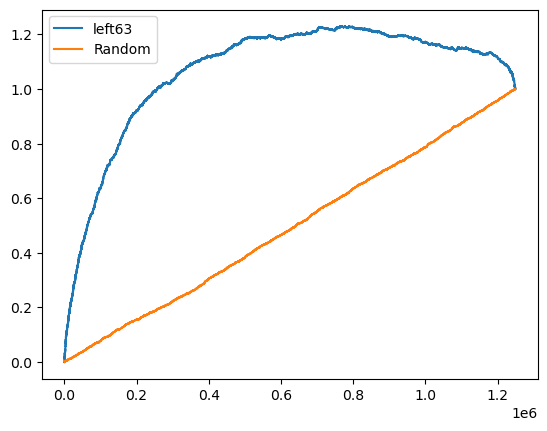

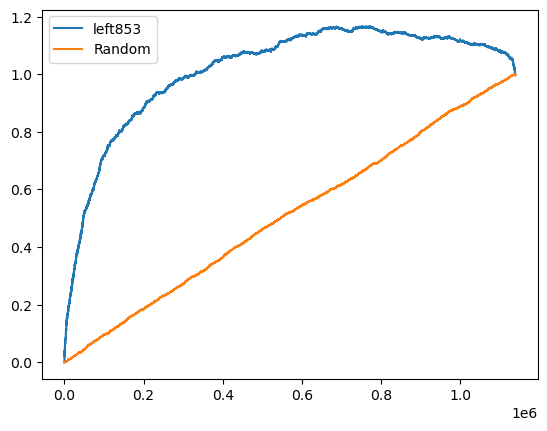

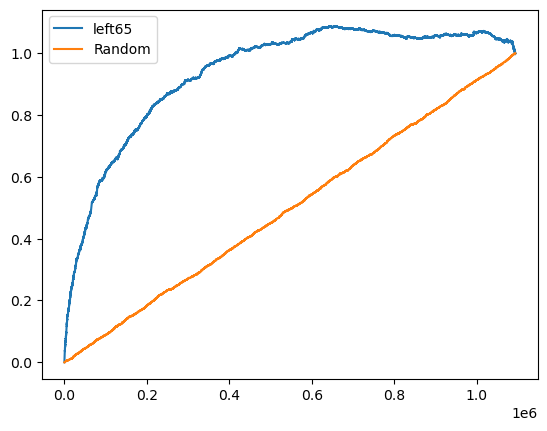

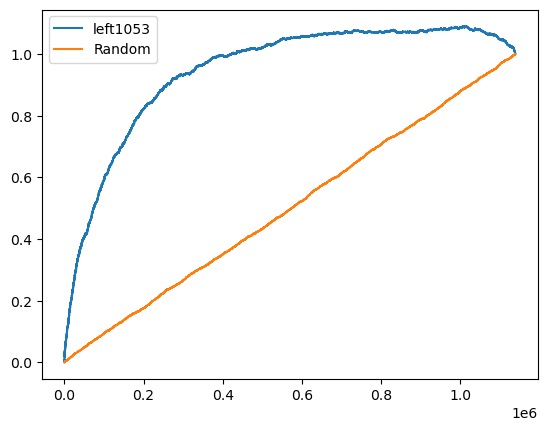

In [23]:
vis.draw_auuc(
    BASE_FMT_eeuen_v2,
    treatments=[1, 2, 3, 4],
    ite_names=['left63', 'left853', 'left65', 'left1053'],
    label_col='label',
    curve_type='auuc',
    real_treatment='real_treatment',
    control_group_name=0,
    show_curve=1
)

left63    1.079045
Random    0.489922
dtype: float64
****************************************
left853    1.041537
Random     0.509462
dtype: float64
****************************************
left65    0.952764
Random    0.496951
dtype: float64
****************************************
left1053    0.954563
Random      0.500602
dtype: float64
****************************************


[left63    1.079045
 Random    0.489922
 dtype: float64,
 left853    1.041537
 Random     0.509462
 dtype: float64,
 left65    0.952764
 Random    0.496951
 dtype: float64,
 left1053    0.954563
 Random      0.500602
 dtype: float64]

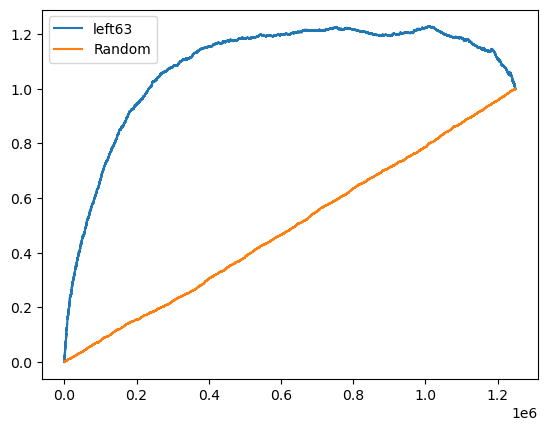

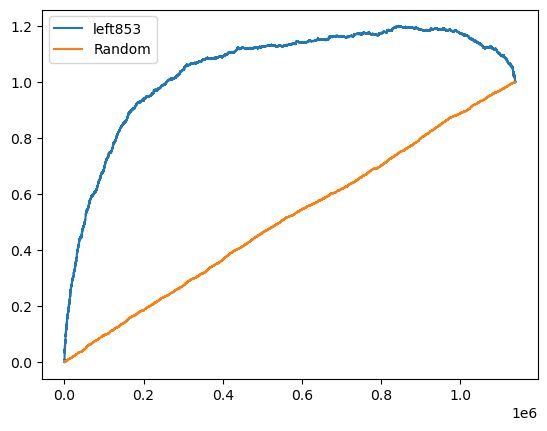

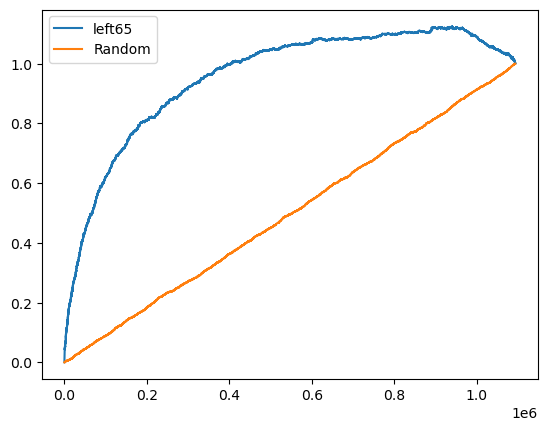

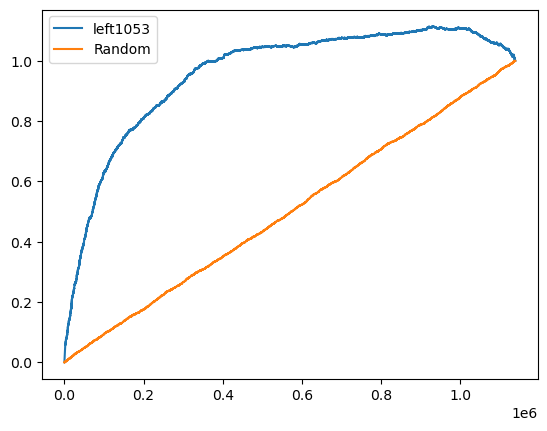

In [24]:
vis.draw_auuc(
    BASE_FMT_eeuen_v3,
    treatments=[1, 2, 3, 4],
    ite_names=['left63', 'left853', 'left65', 'left1053'],
    label_col='label',
    curve_type='auuc',
    real_treatment='real_treatment',
    control_group_name=0,
    show_curve=1
)

left853_minus_left63    0.856584
Random                  0.501300
dtype: float64
****************************************


[left853_minus_left63    0.856584
 Random                  0.501300
 dtype: float64]

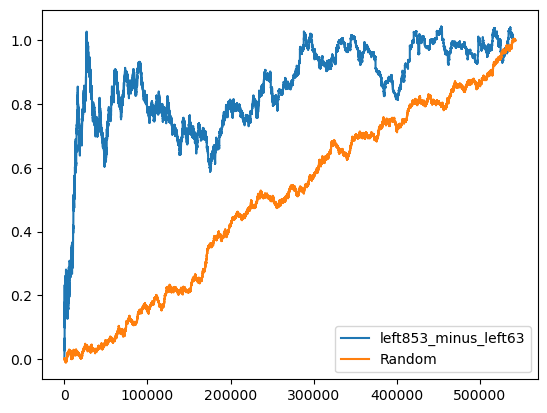

In [26]:
# 从 6张3元 升级到 8元+5张3：
vis.draw_auuc(
    BASE_FMT_eeuen_v3,
    treatments=[2], #8元+5张3
    ite_names=['left853_minus_left63'],
    label_col='label',
    curve_type='auuc',
    real_treatment='real_treatment',
    control_group_name=1,
    show_curve=1
)

left65_minus_left63    0.783780
Random                 0.498795
dtype: float64
****************************************


[left65_minus_left63    0.783780
 Random                 0.498795
 dtype: float64]

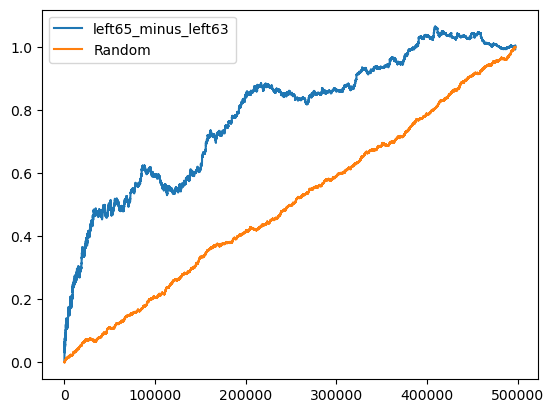

In [27]:
# 从 6张3元 升级到6张5元
vis.draw_auuc(
    BASE_FMT_eeuen_v3,
    treatments=[3],
    ite_names=['left65_minus_left63'],
    label_col='label',
    curve_type='auuc',
    real_treatment='real_treatment',
    control_group_name=1,
    show_curve=1
)

left1053_minus_left63    0.826404
Random                   0.523832
dtype: float64
****************************************


[left1053_minus_left63    0.826404
 Random                   0.523832
 dtype: float64]

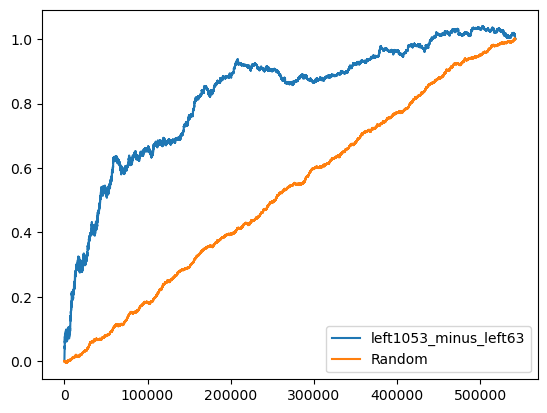

In [28]:
vis.draw_auuc(
    BASE_FMT_eeuen_v3,
    treatments=[4],
    ite_names=['left1053_minus_left63'],
    label_col='label',
    curve_type='auuc',
    real_treatment='real_treatment',
    control_group_name=1,
    show_curve=1
)

In [ ]:
# cost auc

In [ ]:
#pv维度的auc
def caculate_auc(y_labels,y_scores):
    label_unique=list(set(y_labels))
    label_unique.sort(reverse=True)

    # print("label 种类：")
    # print(label_unique)
    f = list(zip(y_scores, y_labels))
    rank = [values2 for values1, values2 in sorted(f, key=lambda x:x[0])] # 根据核销概率进行排序
    cnt=0
    for label in label_unique:
        if label==0:
            continue
        label_dict={}
        for item in label_unique:
            label_dict[item]=0
        #rank根据打分从小到大排序，for循环从小到大遍历到当前标签时，计算前面打分小的label中真正比当前label小的个数
        for i in range(len(rank)):
            if rank[i]==label:
                for item in label_unique:
                    if item<label:
                        cnt+=label_dict[item]

            label_dict[rank[i]]+=1
    label_dict={}
    for item in y_labels:
        if item not in label_dict:
            label_dict[item]=0
        label_dict[item]+=1
    total_len=0
    label_num=len(y_labels)
    for i in range(len(label_unique)-1):
        total_len=total_len+label_dict[label_unique[i]]*(label_num-label_dict[label_unique[i]])
        # print(total_len)
        label_num=label_num-label_dict[label_unique[i]]

    return cnt/total_len

In [ ]:
# euen

In [30]:
def build_euen_eval_df(model_table):
    sql = f"""
    with base as (
        select
            *,
            finish_cnt_7d as label,
            cast(
                (
                    nvl(send_cost, 0.0)
                    + nvl(send_remind_cost, 0.0)
                    + nvl(outcall_cost, 0.0)
                    + nvl(remind_cost, 0.0)
                    + nvl(msg_coupon_cost_7d, 0.0)
                    + nvl(outcall_coupon_cost_7d, 0.0)
                    + nvl(outcall_coupon2_cost_7d, 0.0)
                ) as double
            ) as cost_7d,
            if(nvl(send_success_cnt, 0) > 0 or nvl(outcall_success_cnt, 0) > 0, 1, 0) as exp_label
        from dm.ut_alg_flowback_msg_outcall_label_v2_di
        where dt between '2026-07-23' and '2026-08-06'
          and dt not in ('2026-08-02')
          and new_exp = '迭代流量'
          and (
                group_name_eve in ('留存6张5元', '留存6张3元', '8元留存5张3', '10元留存5张3')
                or (flowtree_group_name = 'DS空白' and group_name_eve = 'control_group')
          )
    ),

    mapping_data as (
        select
            pid,
            label_dt as dt,
            treatment as model_treatment,

            uplift_1 as left63,
            uplift_2 as left853,
            uplift_3 as left65,
            uplift_4 as left1053,

            exp_label as model_exp_label,

            cost_1,
            cost_2,
            cost_3,
            cost_4
        from {model_table}
        where label_dt between '2026-07-23' and '2026-08-06'
          and label_dt not in ('2026-08-02')
    ),

    prediction_agg as (
        select
            bs.*,

            case when bs.group_name_eve = '10元留存5张3' then 4
                 when bs.group_name_eve = '留存6张5元' then 3
                 when bs.group_name_eve = '8元留存5张3' then 2
                 when bs.group_name_eve = '留存6张3元' then 1
                 when bs.group_name_eve = 'control_group' then 0
                 else null
            end as real_treatment,

            mapping_data.model_treatment,

            nvl(mapping_data.left63, 999) as left63,
            nvl(mapping_data.left853, 999) as left853,
            nvl(mapping_data.left65, 999) as left65,
            nvl(mapping_data.left1053, 999) as left1053,

            case
                when nvl(mapping_data.left853, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999
                else mapping_data.left853 - mapping_data.left63
            end as left853_minus_left63,

            case
                when nvl(mapping_data.left65, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999
                else mapping_data.left65 - mapping_data.left63
            end as left65_minus_left63,

            case
                when nvl(mapping_data.left65, 999) = 999 or nvl(mapping_data.left853, 999) = 999 then 999
                else mapping_data.left65 - mapping_data.left853
            end as left65_minus_left853,

            case
                when nvl(mapping_data.left1053, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999
                else mapping_data.left1053 - mapping_data.left63
            end as left1053_minus_left63,

            case
                when nvl(mapping_data.left1053, 999) = 999 or nvl(mapping_data.left853, 999) = 999 then 999
                else mapping_data.left1053 - mapping_data.left853
            end as left1053_minus_left853,

            case
                when nvl(mapping_data.left1053, 999) = 999 or nvl(mapping_data.left65, 999) = 999 then 999
                else mapping_data.left1053 - mapping_data.left65
            end as left1053_minus_left65,

            mapping_data.cost_1,
            mapping_data.cost_2,
            mapping_data.cost_3,
            mapping_data.cost_4,

            mapping_data.model_exp_label

        from base bs
        join mapping_data
          on bs.pid = mapping_data.pid
         and bs.dt = mapping_data.dt
    )

    select *
    from prediction_agg
    """
    return spark.sql(sql).toPandas()

In [31]:
BASE_FMT_euen_v2 = build_euen_eval_df(
    "growstrategy.ut_msg_outcall_euen_timetest_v2_0511_0617_inference_di"
)

BASE_FMT_euen_v3 = build_euen_eval_df(
    "growstrategy.ut_msg_outcall_euen_timetest_v3_0511_0722_inference_di"
)

In [32]:
BASE_FMT_euen_v2.head(25)

,new_exp,group_name,flowtree_group_name,group_name_eve,pid,oneid,send_cnt,send_success_cnt,send_cost,send_remind_cost,outcall_success_cnt,outcall_cost,remind_cost,dau_cnt,dau_cnt_7d,finish_cnt,finish_cnt_7d,msg_coupon_cost,msg_coupon_cost_7d,outcall_coupon_cost,outcall_coupon_cost_7d,outcall_coupon2_cost,outcall_coupon2_cost_7d,fin_order_mini_28d,dt,label,cost_7d,exp_label,real_treatment,model_treatment,left63,left853,left65,left1053,left853_minus_left63,left65_minus_left63,left65_minus_left853,left1053_minus_left63,left1053_minus_left853,left1053_minus_left65,cost_1,cost_2,cost_3,cost_4,model_exp_label
0,迭代流量,DS空白,DS空白,control_group,1000424808450,v1_17592737514504,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0,2026-07-26,0.0,0.000,0,0,0,0.000458,-0.000865,0.003113,0.009872,-0.001323,0.002655,0.003978,0.009414,0.010737,0.006759,0.036452,0.041244,0.086551,0.066587,0
1,迭代流量,探索,探索,8元留存5张3,1002071531521,v1_17592507480090,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,2026-07-29,0.0,0.000,0,2,2,0.007670,0.008605,0.010061,0.017561,0.000935,0.002391,0.001456,0.009891,0.008956,0.007501,0.033569,0.033955,0.046511,0.072103,0
2,迭代流量,DS空白,DS空白,control_group,100236101,v1_17593051460290,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,36.0,2026-08-05,0.0,0.000,0,0,0,0.007315,0.007600,0.010547,0.017141,0.000286,0.003232,0.002947,0.009827,0.009541,0.006594,0.023486,0.020415,0.043811,0.057783,0
3,迭代流量,探索,探索,留存6张5元,1002405367808,v1_17592784724585,2.0,1.0,0.021,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,2026-07-28,0.0,0.021,1,3,3,0.128698,0.150764,0.150305,0.206088,0.022066,0.021607,-0.000458,0.077390,0.055325,0.055783,0.309563,0.702561,0.720999,1.058767,1
4,迭代流量,DS空白,DS空白,control_group,10027190,v1_17592415684825,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,2026-08-05,0.0,0.000,0,0,0,0.007985,0.009084,0.010232,0.016751,0.001099,0.002247,0.001148,0.008766,0.007667,0.006519,0.044139,0.042571,0.052597,0.078574,0
5,迭代流量,探索,探索,留存6张3元,1004284157952,v1_17592700211369,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,21.0,2026-07-27,0.0,0.000,0,1,1,0.008521,0.009151,0.011105,0.017557,0.000631,0.002585,0.001954,0.009037,0.008406,0.006452,0.026966,0.024693,0.047269,0.061446,0
6,迭代流量,探索,探索,留存6张3元,100505820,v1_17592697272634,2.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0,2026-07-28,0.0,0.000,0,1,1,0.004685,0.005250,0.008308,0.013972,0.000565,0.003623,0.003058,0.009287,0.008722,0.005664,0.013757,0.009448,0.029959,0.044458,0
7,迭代流量,DS空白,DS空白,control_group,100544815109,v1_17592763834195,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,2026-07-26,0.0,0.000,0,0,0,0.005554,0.002952,0.009645,0.019748,-0.002602,0.004091,0.006694,0.014195,0.016797,0.010103,0.036032,0.053689,0.084505,0.106696,0
8,迭代流量,DS空白,DS空白,control_group,100783534,v1_17592940343724,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,29.0,2026-07-25,0.0,0.000,0,0,0,0.000512,0.001620,0.003752,0.009196,0.001108,0.003241,0.002132,0.008684,0.007576,0.005444,0.000204,-0.013289,0.014442,0.039398,0
9,迭代流量,DS空白,DS空白,control_group,100859248,v1_17592707271195,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,2026-08-06,0.0,0.000,0,0,0,0.006111,0.006859,0.009475,0.014441,0.000748,0.003364,0.002616,0.008330,0.007581,0.004965,0.015472,0.010246,0.027625,0.049283,0


In [33]:
BASE_FMT_euen_v3.head(25)

,new_exp,group_name,flowtree_group_name,group_name_eve,pid,oneid,send_cnt,send_success_cnt,send_cost,send_remind_cost,outcall_success_cnt,outcall_cost,remind_cost,dau_cnt,dau_cnt_7d,finish_cnt,finish_cnt_7d,msg_coupon_cost,msg_coupon_cost_7d,outcall_coupon_cost,outcall_coupon_cost_7d,outcall_coupon2_cost,outcall_coupon2_cost_7d,fin_order_mini_28d,dt,label,cost_7d,exp_label,real_treatment,model_treatment,left63,left853,left65,left1053,left853_minus_left63,left65_minus_left63,left65_minus_left853,left1053_minus_left63,left1053_minus_left853,left1053_minus_left65,cost_1,cost_2,cost_3,cost_4,model_exp_label
0,迭代流量,DS空白,DS空白,control_group,1000424808450,v1_17592737514504,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0,2026-07-26,0.0,0.000,0,0,0,0.008506,0.011700,0.016698,0.018517,0.003194,0.008193,0.004999,0.010012,0.006818,0.001819,0.033801,0.068790,0.102638,0.077694,0
1,迭代流量,探索,探索,8元留存5张3,1002071531521,v1_17592507480090,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,2026-07-29,0.0,0.000,0,2,2,0.010522,0.011509,0.017327,0.025370,0.000987,0.006805,0.005818,0.014848,0.013861,0.008043,0.062714,0.108500,0.181053,0.174097,0
2,迭代流量,DS空白,DS空白,control_group,100236101,v1_17593051460290,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,36.0,2026-08-05,0.0,0.000,0,0,0,0.007008,0.009485,0.015907,0.014935,0.002478,0.008899,0.006421,0.007927,0.005449,-0.000972,0.030766,0.049318,0.077723,0.080547,0
3,迭代流量,探索,探索,留存6张5元,1002405367808,v1_17592784724585,2.0,1.0,0.021,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,2026-07-28,0.0,0.021,1,3,3,0.074571,0.083548,0.096843,0.117561,0.008977,0.022272,0.013295,0.042991,0.034013,0.020718,0.251316,0.464326,0.628914,0.722266,1
4,迭代流量,DS空白,DS空白,control_group,10027190,v1_17592415684825,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,2026-08-05,0.0,0.000,0,0,0,0.004889,0.005788,0.014728,0.011894,0.000899,0.009839,0.008939,0.007005,0.006106,-0.002834,0.044198,0.054097,0.086991,0.104864,0
5,迭代流量,探索,探索,留存6张3元,1004284157952,v1_17592700211369,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,21.0,2026-07-27,0.0,0.000,0,1,1,0.005880,0.006852,0.014819,0.013559,0.000971,0.008939,0.007967,0.007679,0.006707,-0.001260,0.033306,0.053014,0.080595,0.079622,0
6,迭代流量,探索,探索,留存6张3元,100505820,v1_17592697272634,2.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0,2026-07-28,0.0,0.000,0,1,1,0.006186,0.008012,0.013771,0.013234,0.001826,0.007584,0.005759,0.007048,0.005222,-0.000536,0.026596,0.040945,0.074348,0.065057,0
7,迭代流量,DS空白,DS空白,control_group,100544815109,v1_17592763834195,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,2026-07-26,0.0,0.000,0,0,0,0.010566,0.011015,0.016054,0.024586,0.000449,0.005488,0.005039,0.014020,0.013571,0.008532,0.039487,0.093839,0.181711,0.179052,0
8,迭代流量,DS空白,DS空白,control_group,100783534,v1_17592940343724,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,29.0,2026-07-25,0.0,0.000,0,0,0,-0.000703,-0.000657,0.011897,0.000569,0.000046,0.012600,0.012554,0.001271,0.001225,-0.011329,0.014502,0.027942,0.051286,0.022673,0
9,迭代流量,DS空白,DS空白,control_group,100859248,v1_17592707271195,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,2026-08-06,0.0,0.000,0,0,0,0.004482,0.006228,0.014763,0.010258,0.001746,0.010281,0.008535,0.005776,0.004031,-0.004505,0.031790,0.043981,0.065432,0.075553,0


left63    0.974209
Random    0.489922
dtype: float64
****************************************
left853    0.934364
Random     0.509462
dtype: float64
****************************************
left65    0.874515
Random    0.496951
dtype: float64
****************************************
left1053    0.910685
Random      0.500602
dtype: float64
****************************************


[left63    0.974209
 Random    0.489922
 dtype: float64,
 left853    0.934364
 Random     0.509462
 dtype: float64,
 left65    0.874515
 Random    0.496951
 dtype: float64,
 left1053    0.910685
 Random      0.500602
 dtype: float64]

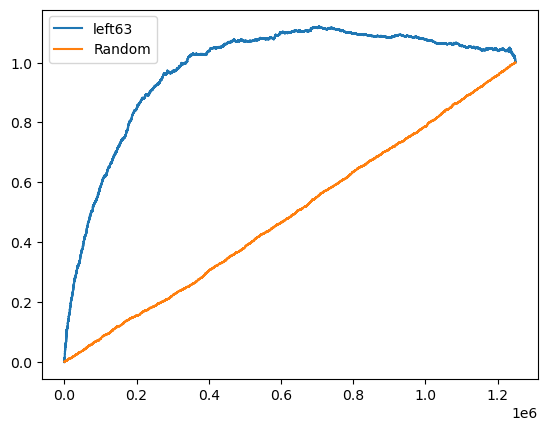

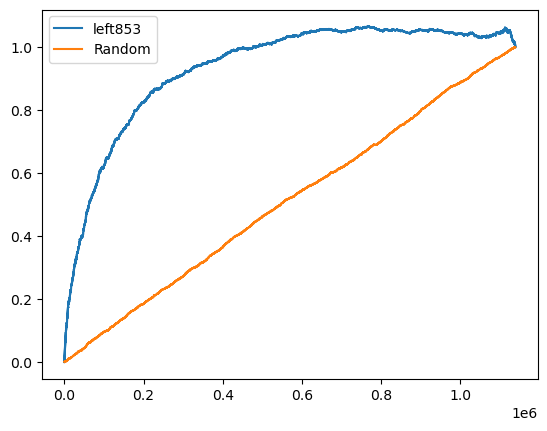

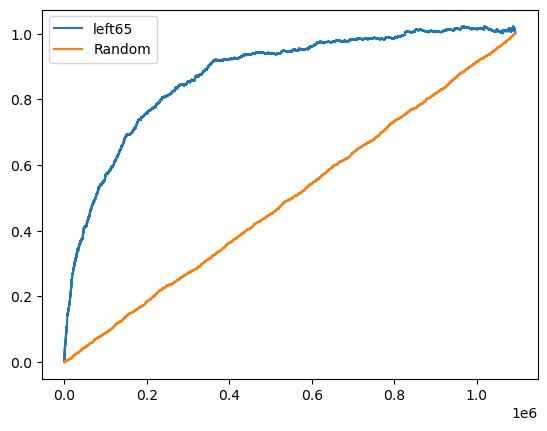

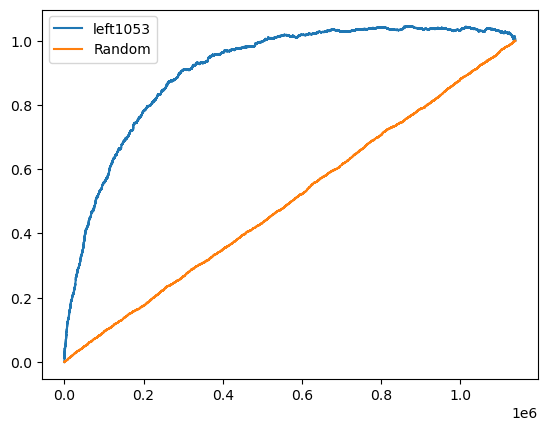

In [34]:
vis.draw_auuc(
    BASE_FMT_euen_v2,
    treatments=[1, 2, 3, 4],
    ite_names=['left63', 'left853', 'left65', 'left1053'],
    label_col='label',
    curve_type='auuc',
    real_treatment='real_treatment',
    control_group_name=0,
    show_curve=1
)

left63    0.977650
Random    0.489922
dtype: float64
****************************************
left853    0.944353
Random     0.509462
dtype: float64
****************************************
left65    0.885760
Random    0.496951
dtype: float64
****************************************
left1053    0.911709
Random      0.500602
dtype: float64
****************************************


[left63    0.977650
 Random    0.489922
 dtype: float64,
 left853    0.944353
 Random     0.509462
 dtype: float64,
 left65    0.885760
 Random    0.496951
 dtype: float64,
 left1053    0.911709
 Random      0.500602
 dtype: float64]

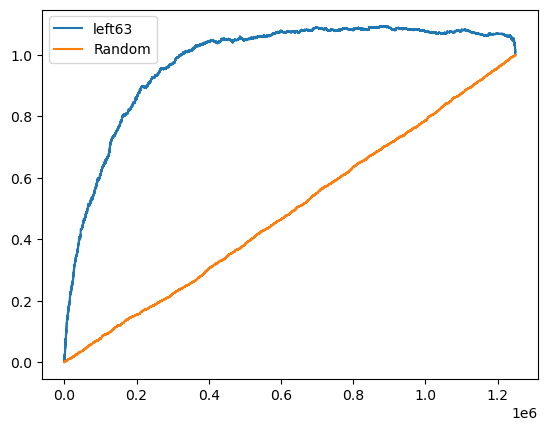

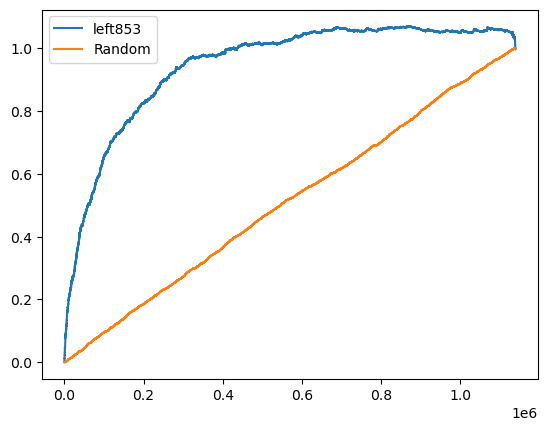

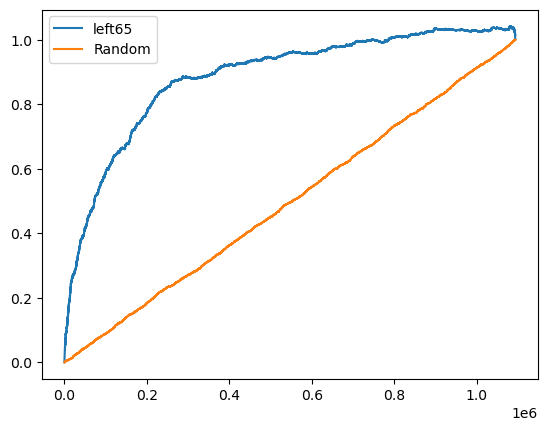

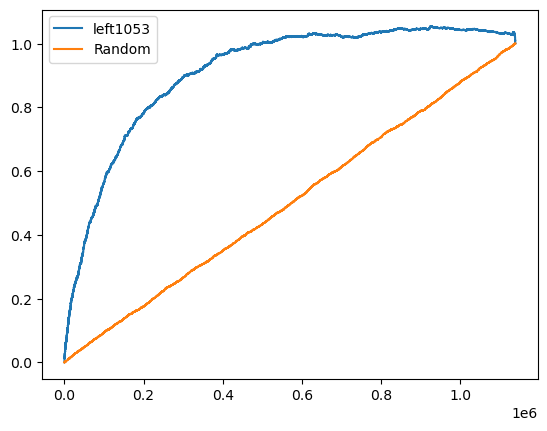

In [35]:
vis.draw_auuc(
    BASE_FMT_euen_v3,
    treatments=[1, 2, 3, 4],
    ite_names=['left63', 'left853', 'left65', 'left1053'],
    label_col='label',
    curve_type='auuc',
    real_treatment='real_treatment',
    control_group_name=0,
    show_curve=1
)